In [1]:
# Importing necessary packages
import numpy as np # Supports arrays, matrices, etc. and the mathematical functions to operate them
import matplotlib.pyplot as plt # For creating plots
import pandas as pd # Data handling 
import pyp2options # Custom library --> don't know what it does yet
from astropy.coordinates import SkyCoord # Represents and converts astronomical coordinates
import astropy.units as u # Handles physical units
import scipy.optimize as spopt # Contains optimization algorithms
import sys 

from matplotlib.backends.backend_pdf import PdfPages # Saves multiple matplotlib figures into a single PDF file

In [2]:
# Required arguments
field = 'MISHAPS_F1_DITH0'
chip = 'N10'
mag = 'r'
c1 = 'r'  
c2 = 'z'  
fc = f"{field}_{chip}" # # Combined field_chip string
    
#g-i values for CMD analysis
colorcut = 1.06
magcut = 17.3
cmin=0.0
cmax=2.0
mstoshift=3.5 # Main Sequence Turn-Off shift value

# Adjusts cut values based on filter choices
if c2=="z" and c1=="r":
    colorcut=0.46
    cmax=1.0
    mstoshift=3.0 
interactive = False # Default = False, determines whether to have interactive plots

# Check if interactive plotting is enabled
if len(sys.argv)>=6:
    interactive=True

# Optional override for color cut
if len(sys.argv)>=7:
    colorcut = float(sys.argv[6])
    print("colorcut =",colorcut)

# Optional override for magnitude cut
if len(sys.argv)>=8:
    magcut = float(sys.argv[7])
    print("magcut =",magcut)

print("mag c1 c2",mag,c1,c2)

# Optional RA/Dec region cuts (positional filtering)
amin=-1 # All four of these default to -1; min and max RA and Dec to use if doing a position cut
amax=-1
dmin=-1
dmax=-1
poscut=False # Default = False, whether to do a position cut
if len(sys.argv)>=9:
    amin=float(sys.argv[8])
    amax=float(sys.argv[9])
    dmin=float(sys.argv[10])
    dmax=float(sys.argv[11])
    poscut=True

mag c1 c2 r r z


In [3]:
opt = pyp2options.pip2options('/home/bernthold.17/SURP2025/rcfit/')

qmcol=opt['cmdq-' + mag]-1 # Quality flag column for 'mag' band
qc1col=opt['cmdq-' + c1]-1 # Quality flag column for 'c1' band
qc2col=opt['cmdq-' + c2]-1 # Quality flag column for 'c2' band

mcol=opt['cmdm-' + mag]-1 # Magnitude column in cmd file for 'mag' band
c1col=opt['cmdm-' + c1]-1 # Magnitude column in cmd file for 'c1' band
c2col=opt['cmdm-' + c2]-1 # Magnitude column in cmd file for 'c2' band

acol=1 # RA column
dcol=2 # Dec column


refdir = opt['refdir']
#refdir = '/Users/penny/mishaps/scratch/redclump'
#refdir = '/Volumes/olympus/mishaps/ref/Jan2022'
refdir = '/home/bernthold.17/SURP2025/rcfit'

# This has something to do with the image size down from 2048x4096 to 512x512
nx=4
ny=8
size=2048.0/nx

/home/bernthold.17/SURP2025/rcfit/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)


In [4]:
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0,0)
def rccolor(l,b):
    # Function for getting the known color of the red clump at a given l and b coordinate
    # Gives the g, r, i, and z photometry for the red clump, RGB branch, and AGB branch;
    # the distance to the red clump at that l and b; and the distance modulus mu
    # mu = m - M = 5*log10(d) - 5; https://en.wikipedia.org/wiki/Distance_modulus
    
    I0 = 14.3955 - 0.0239*l + 0.0122*np.abs(b) #Dereddened I mag of red clump
    I = np.array([I0,I0+0.737,I0-1.07]) #of RC, RGBB & AGBB
    dmod = I-14.3955 + 5.0*np.log10(8178.0)-5.0 #Distance modulus of bar density peak
    d = 10**(0.2*(dmod+5)) #distance
    V = 1.060+I            #V mag of clump (note RGBB and AGBB V will be wrong)
    
    # Use the relations between UBVRI and SDSS ugriz to get the griz mags
    gs = V+0.553           #g sdss                        
    rs = V-0.327           #r sdss
    i_s = V-0.600          #i sdss

    gmi = gs-i_s           #(g-i) sdss
    
    # rgbb = red giant branch, agbb = asymptotic giant branch
    rgbb_rs = 1.060+I+0.737-0.327
    agbb_rs = 1.060+I-1.070-0.327
    rgbb_gmi = 0.553+0.600-0.06
    agbb_gmi = 0.553+0.600+0.2

    print("rs",rs,rgbb_rs,agbb_rs)
    print("gmi",gmi,rgbb_gmi,agbb_gmi)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0,10):                                                  
        gpmgs = -0.01808 -0.13595*gmi +0.01941*gmi**2 -0.00183*gmi**3
        rpmrs = -0.01836 -0.03577*gmi +0.02612*gmi**2 -0.00558*gmi**3
        ipmis = 0.01170 -0.00400*gmi +0.00066*gmi**2 -0.00058*gmi**3
        gp=gs+gpmgs #g panstarrs
        rp=rs+rpmrs #r panstarrs
        ip=i_s+ipmis #i panstarrs
        gmi=gp-ip #gmi panstarrs
        rmi=rp-ip #rmi panstarrs
        imz=0.234625+0.211715*(gmi-1.25) #i-z panstarrs
        rmz=rmi+imz #r-z panstarrs
        zp = rp-rmz #z panstarrs

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":gp[0],"clump-r":rp[0],"clump-i":ip[0],"clump-z":zp[0],
           "rgbb-g":gp[1], "rgbb-r":rp[1], "rgbb-i":ip[1], "rgbb-z":zp[1],
           "agbb-g":gp[2], "agbb-r":rp[2], "agbb-i":ip[2], "agbb-z":zp[2],
           "distance":d[0], "dmod":dmod[0]}

        
        

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

def rcmodel(x,A,B,rcmag,Nrc,src):
    #print(zrc,zrc+rgbbz0,zrc+agbbz0)
    return A*np.exp(B*(x-rcmag)) + \
           Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-rcmag)**2/src**2) + \
           0.201*Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-(rcmag+rgbbmag0))**2/src**2) + \
           0.028*Nrc/(np.sqrt(2*np.pi*src**2))*np.exp(-0.5*(x-(rcmag+agbbmag0))**2/src**2)

def cgauss(x,Nrc,crc,sc):
    return Nrc/(np.sqrt(2*np.pi*sc**2))*np.exp(-0.5*(x-crc)**2/sc**2)




cmdo = pd.read_csv('/home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_DITH0_N10.cmd.calibrate_ps', header = None, sep = '\\s+')

In [5]:
print(cmdo.shape)
#print(cmd.iloc[:,qrcol],cmd.iloc[:,qzcol])
cmd = cmdo[(cmdo.iloc[:,qc1col]==1) & (cmdo.iloc[:,qc2col]==1)]

# If you've given it an explicit position cut, use those values. Else use the min and max RA and Dec from the data
if poscut==True:
    cmd = cmd[(cmd.iloc[:,acol]>=amin) & (cmd.iloc[:,acol]<amax) & (cmd.iloc[:,dcol]>=dmin) & (cmd.iloc[:,dcol]<dmax)]
else:
    amin = np.nanmin(cmd.iloc[:,acol])
    amax = np.nanmax(cmd.iloc[:,acol])
    dmin = np.nanmin(cmd.iloc[:,dcol])
    dmax = np.nanmax(cmd.iloc[:,dcol])
print(cmd.shape)

(101166, 67)
(34630, 67)


In [6]:
# Get the mean RA and Dec
a = np.nanmean(cmd.iloc[:,1])
d = np.nanmean(cmd.iloc[:,2])

# Get l and b coordinates
coords = SkyCoord(a,d,frame='icrs',unit=u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
print(l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
clump = rccolor(l,b)

clumpmag0 = clump["clump-"+mag]
rgbbmag0 = clump["rgbb-"+mag]
agbbmag0 = clump["agbb-"+mag]

4.835380350737622 -7.9030828497424155
rs [15.10935202 15.84635202 14.03935202] [15.84635202 16.58335202 14.77635202] [14.03935202 14.77635202 12.96935202]
gmi [1.153 1.153 1.153] 1.093 1.353


In [7]:
print(clump["clump-"+mag],clump["dmod"],clump["distance"]) # mag = PanSTARRS mag ,dmod = distance modulus, distance (pc)
print(clump["clump-r"]-clump["clump-z"],clump["clump-g"]-clump["clump-i"]) # Colors 
print(mag+"0-clump,rgbb,agbb",clump["clump-"+mag],clump["rgbb-"+mag],clump["agbb-"+mag])

15.075760459462273 14.544087551475812 8106.20365163474
0.415050956235401 1.0079866656149221
r0-clump,rgbb,agbb 15.075760459462273 15.812760459462273 14.005760459462273


In [8]:
# Filter for the giants
giants = cmd[(cmd.iloc[:,mcol]<magcut) & (cmd.iloc[:,c1col]-cmd.iloc[:,c2col]>colorcut)]
print(giants.shape)

# Bins the magnitudes of the giants, be is bin edges
hist,be = np.histogram(giants.iloc[:,mcol],range=(magcut-4.0,magcut),bins=40,density=False)
bc = 0.5*(be[0:-1]+be[1:]) # Calculates bin centers from the bin edges

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask = (hist>0)
hist=hist[mask]
bc=bc[mask]

(1529, 67)


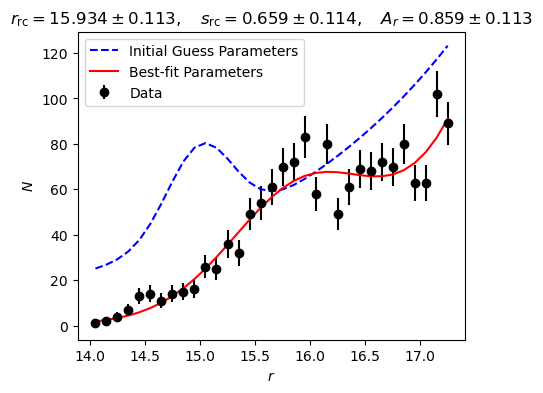

In [9]:
plt.figure(figsize=(5,4))
plt.tight_layout()
plt.errorbar(bc,hist,yerr=np.sqrt(hist),fmt='ko', label = 'Data') # Plot the histogram as points

guess = [40.0,0.5,15.0,30.0,0.3] # Initial guess for the curve fit

# use curve fit to try fitting the histogram data to the rcmodel function
# first argument is the function, second is the bin centers, third is the histogram values
# p0 is your initial guess for the parameters
# sigma is the uncertainty, the square root of the histogram is a close enough approximation
par,cov = spopt.curve_fit(rcmodel,bc,hist,p0=guess,sigma=np.sqrt(hist))

# par an array of the best-fit parameters, this sets each parameter to its own variable
# cov is the array of errors from the fit, I think technically as a covariance matrix
A,B,magrc,Nrc,src = par

# Plot your initial guess in blue and the best fit in red
plt.plot(bc,rcmodel(bc,*guess),'b--', label = 'Initial Guess Parameters')
plt.plot(bc,rcmodel(bc,*par),'r-', label = 'Best-fit Parameters')

plt.xlabel(r'$%s$' % (mag))
plt.ylabel(r'$N$')

plt.title(r'$%s_{\rm rc}=%6.3f\pm%5.3f,\quad s_{\rm rc}=%6.3f\pm%5.3f,' \
              '\quad A_%s=%5.3f\pm%5.3f$' % (mag, magrc, np.sqrt(cov[2,2]), src, np.sqrt(cov[4,4]),
                                             mag, magrc-clumpmag0, np.sqrt(cov[2,2])))
plt.legend(loc='best')
plt.show()

In [10]:
# From the giants, select only the red clump 
clumponly = giants[np.abs(giants.iloc[:,mcol]-magrc)<2*src]
hist2,be2 = np.histogram(clumponly.iloc[:,c1col]-clumponly.iloc[:,c2col],range=(colorcut,colorcut+1.5),bins=60,density=False)
bc2 = 0.5*(be2[0:-1]+be2[1:])
print(clumponly.shape)

from scipy.stats import gaussian_kde

# Original data
mag_data = giants.iloc[:,mcol]  
col_data = clumponly.iloc[:,c1col] - clumponly.iloc[:,c2col]

# Filter out extreme values (if any) to avoid over-smoothing
mag_data = mag_data[(mag_data > 14) & (mag_data < 18)]
col_data = col_data[(col_data > 0.5) & (col_data < 1.6)]

# Fit KDE
kde_mag = gaussian_kde(mag_data)
kde_col = gaussian_kde(col_data)

# Evaluation grid
x_mag = np.linspace(np.min(mag_data), np.max(mag_data), 200)
x_col = np.linspace(np.min(col_data), np.max(col_data), 200)

# Evaluate KDE
kde_mag_vals = kde_mag(x_mag)
kde_col_vals = kde_col(x_col)

#plt.plot(x_mag, kde_mag_vals, 'r-', lw=2, label='KDE')
#plt.plot(x_col, kde_col_vals, 'r-', lw=2, label='KDE')

(1445, 67)


KDE peak magnitude: 17.007


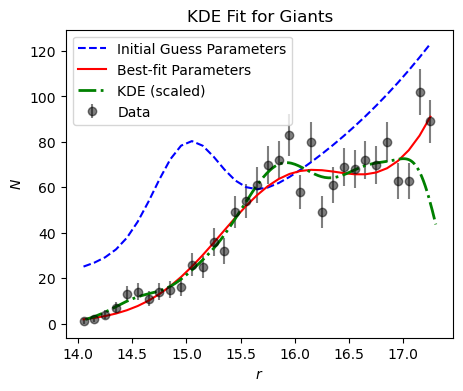

In [11]:
peak_mag_ind = np.argmax(kde_mag_vals)
peak_mag_kde = x_mag[peak_mag_ind]
print(f"KDE peak magnitude: {peak_mag_kde:.3f}")

plt.figure(figsize=(5,4))
plt.tight_layout()
plt.errorbar(bc,hist,yerr=np.sqrt(hist),fmt='ko', label = 'Data', alpha = 0.5)

plt.plot(bc,rcmodel(bc,*guess),'b--', label = 'Initial Guess Parameters')
plt.plot(bc,rcmodel(bc,*par),'r-', label = 'Best-fit Parameters')

# Scale KDE so it matches the historgrams vertical scale
bin_width = be[1] - be[0]
kde_mag_vals_scaled = kde_mag_vals * len(mag_data) * bin_width
plt.plot(x_mag, kde_mag_vals_scaled, 'g-.', lw=2, label='KDE (scaled)')

plt.xlabel(r'$%s$' % (mag))
plt.ylabel(r'$N$')

plt.title('KDE Fit for Giants')
#plt.title(r'$%s_{\rm rc}=%6.3f\pm%5.3f,\quad s_{\rm rc}=%6.3f\pm%5.3f,' \
              # '\quad A_%s=%5.3f\pm%5.3f$' % (mag, magrc, np.sqrt(cov[2,2]), src, np.sqrt(cov[4,4]),
                                             #mag, magrc-clumpmag0, np.sqrt(cov[2,2])))
plt.legend(loc='best')
plt.show()

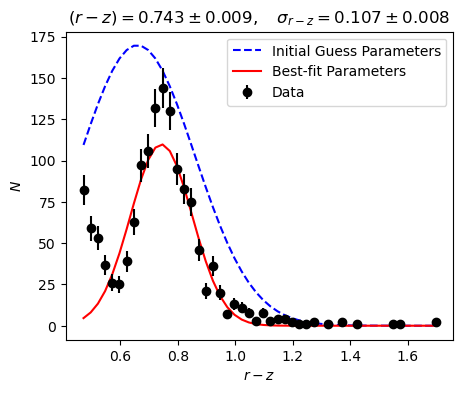

In [12]:
hist2mask = (hist2>0)
hist2 = hist2[hist2mask]
bc2=bc2[hist2mask]

guess2 = [par[3]+0.0,colorcut+0.2,0.2]
par2,cov2 = spopt.curve_fit(cgauss,bc2,hist2,p0=guess2,sigma=np.sqrt(hist2))

plt.figure(figsize = (5,4))
plt.tight_layout()

plt.plot(bc2,cgauss(bc2,*guess2),'b--', label = 'Initial Guess Parameters')
plt.plot(bc2,cgauss(bc2,*par2),'r-', label = 'Best-fit Parameters')
plt.errorbar(bc2,hist2,yerr=np.sqrt(hist2),fmt='ko', label = 'Data')

plt.title(r'$(%s-%s)=%6.3f\pm%5.3f,\quad \sigma_{%s-%s}=%6.3f\pm%5.3f$' % (c1,c2,par2[1],np.sqrt(cov2[1,1]),c1,c2,par2[2],np.sqrt(cov2[2,2])))
plt.xlabel(r'$%s-%s$' % (c1,c2))
plt.ylabel(r'$N$')

plt.legend(loc='best')
plt.show()

KDE peak magnitude: 0.740


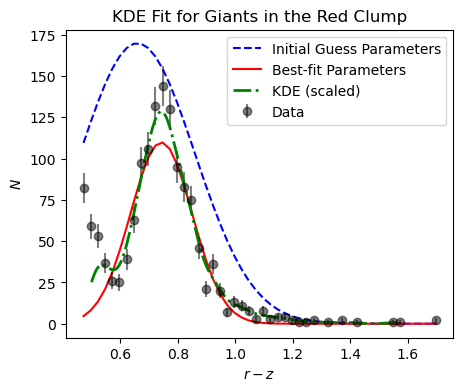

In [13]:
peak_col_ind = np.argmax(kde_col_vals)
peak_col_kde = x_col[peak_col_ind]
print(f"KDE peak magnitude: {peak_col_kde:.3f}")

plt.figure(figsize = (5,4))
plt.tight_layout()

plt.plot(bc2,cgauss(bc2,*guess2),'b--', label = 'Initial Guess Parameters')
plt.plot(bc2,cgauss(bc2,*par2),'r-', label = 'Best-fit Parameters')
plt.errorbar(bc2,hist2,yerr=np.sqrt(hist2),fmt='ko', label = 'Data', alpha = 0.5)

# Scale KDE so it matches the historgrams vertical scale
bin_width = be2[1] - be2[0]
kde_col_vals_scaled = kde_col_vals * len(col_data) * bin_width
plt.plot(x_col, kde_col_vals_scaled, 'g-.', lw=2, label='KDE (scaled)')

#plt.title(r'$(%s-%s)=%6.3f\pm%5.3f,\quad \sigma_{%s-%s}=%6.3f\pm%5.3f$' % (c1,c2,par2[1],np.sqrt(cov2[1,1]),c1,c2,par2[2],np.sqrt(cov2[2,2])))
plt.title('KDE Fit for Giants in the Red Clump')
plt.xlabel(r'$%s-%s$' % (c1,c2))
plt.ylabel(r'$N$')

plt.legend(loc='best')
plt.show()

In [14]:
#bin statistic, scipy.statistics.binnedstatistic --> bin the data, gives a binned median value of a range of colors
#look in ali's code for examples